#### 선형회귀(Linear regression)
- 입력과 출력간의 관계를 (선형으로 놓고) 알아내는 것
    - 광고비와 매출액의 관계
- 목적: 최적의 기울기와 절편 구하기
    - 실제값과 예측값의 오차가 최소화 되게 구하는게 목적
    - MSE 사용
- 경사하강법 사용

In [3]:
import torch
import matplotlib.pyplot as plt

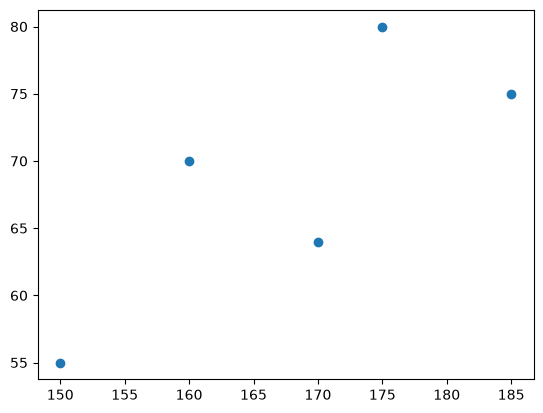

In [5]:
x=torch.tensor([150., 160, 170, 175, 185])
y=torch.tensor([55, 70, 64, 80, 75.])
N=len(x)

plt.plot(x, y, 'o')

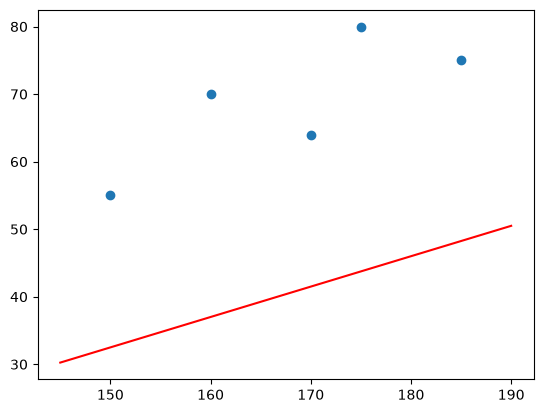

In [7]:
# 임의로 기울기와 절편 설정
a=0.45      # 기울기
b=-35       # 절편

x_plot=torch.linspace(145, 190, 100)
y_plot=a * x_plot + b

plt.figure()
plt.plot(x, y, 'o')                 # 실제 키와 몸무게
plt.plot(x_plot, y_plot, 'r')       # 임의로 만든 선형

(0.0, 1000.0)

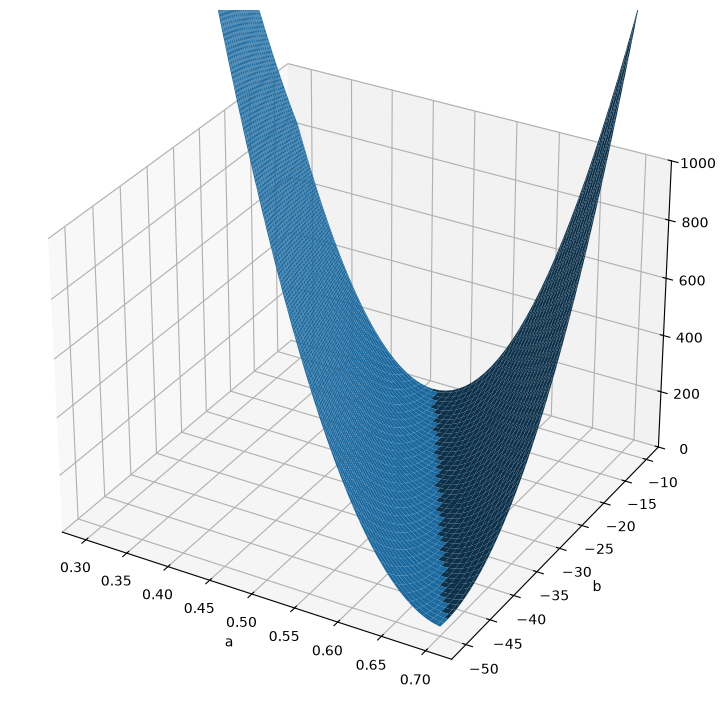

In [13]:
a=0.5+torch.linspace(-0.2, 0.2, 100)        # 0.3~0.7 기울기 후보군
b=-30+torch.linspace(-20, 20, 100)          # -50~-10 절편 후보군

L=torch.zeros(len(a), len(b))

for i in range(len(a)):
    for j in range(len(b)):
        for n in range(N):
            L[i, j]=L[i, j] + (y[n] - (a[i]*x[n]+b[j]))**2

L=L/N # MSE

plt.figure(figsize=[10, 9])
ax=plt.axes(projection="3d")
A, B=torch.meshgrid(a, b, indexing='ij')

ax.plot_surface(A, B, L)
ax.set_xlabel('a')
ax.set_ylabel('b')
ax.set_zlim([0, 1000])

In [14]:
print(torch.min(L))
a_opt=A[L==torch.min(L)]
b_opt=B[L==torch.min(L)]

print(f'optimal a={a_opt}')     # 기울기 최적
print(f'optimal a={b_opt}')     # 절편 최적

tensor(29.0315)
optimal a=tensor([0.5626])
optimal a=tensor([-25.7576])


In [ ]:
x_plot=torch.linspace(145, 190, 100)
# y_plot=a_opt*

#### 경사하강법

In [24]:
# a=torch.tensor([[0.45]], requires_grad=True)
# b=torch.tensor([-35.], requires_grad=True)

# LR=3e-6     #0.0000003
# EPOCH=20

# loss_history=[]

# for ep in range[EPOCH]:
#     y_hat=a*x+b

#     loss=0
#     for n in range(N):
#         loss+=(y[n]-y_hat[n])**2
#     loss=loss/N

#     loss.backward()

#     with torch.no_grad():
#         a-=LR*a.grad
#         b-=LR*b.grad

#     a.grad=torch.tensor([0.])
#     b.grad=torch.tensor([0.])

#     loss_history+=[loss.item()]

#     print(f'Epoch:{ep+1}, train loss:{loss.item():.4f}')
#     print(f'Weight:{a.item():.4f}, Bias:{b.item():.4f}')

#     x_plot=torch.linspace(145, 190, 100)
#     y_plot=a.detach() * x_plot+b.detach()
#     plt.figure()

TypeError: type 'range' is not subscriptable

Epoch: 1, train loss: 900.5650
Weight: 0.4780, Bias:-34.9998


c:\Users\mega\KDH\PyTorch\.ven\Lib\site-packages\torch\nn\modules\loss.py:630: UserWarning: Using a target size (torch.Size([5])) that is different to the input size (torch.Size([5, 1])). This will likely lead to incorrect results due to broadcasting. Please ensure they have the same size.
  return F.mse_loss(input, target, reduction=self.reduction)


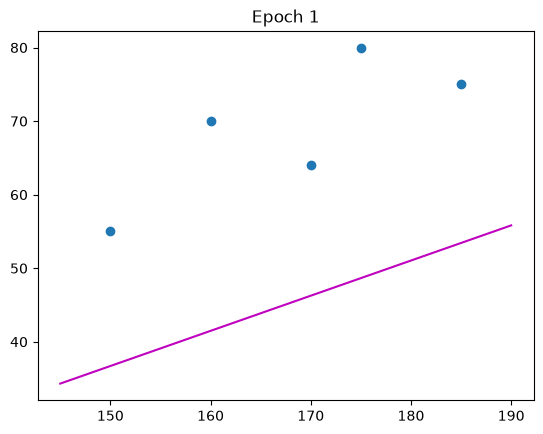

Epoch: 2, train loss: 660.9294
Weight: 0.5013, Bias:-34.9997


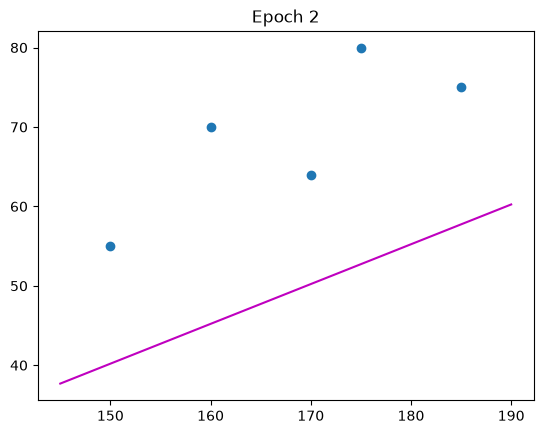

Epoch: 3, train loss: 495.9343
Weight: 0.5206, Bias:-34.9996


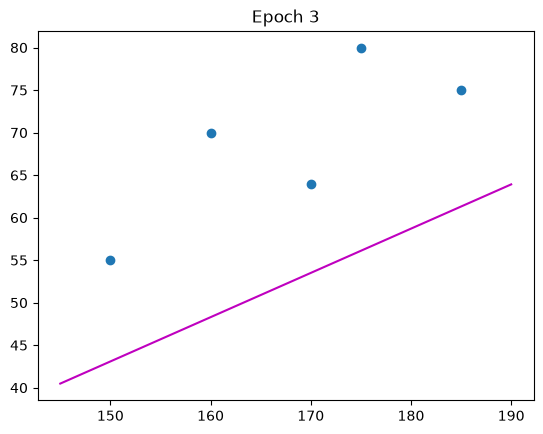

Epoch: 4, train loss: 382.3307
Weight: 0.5366, Bias:-34.9995


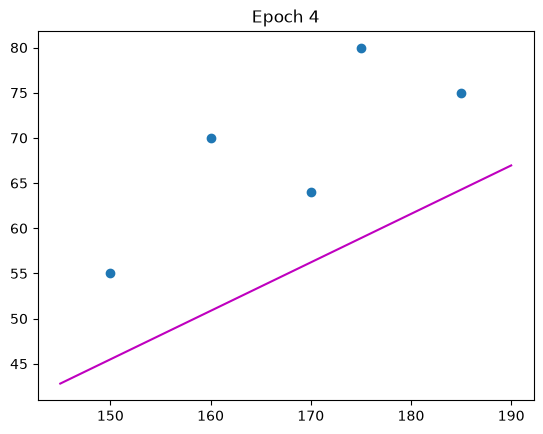

Epoch: 5, train loss: 304.1121
Weight: 0.5499, Bias:-34.9994


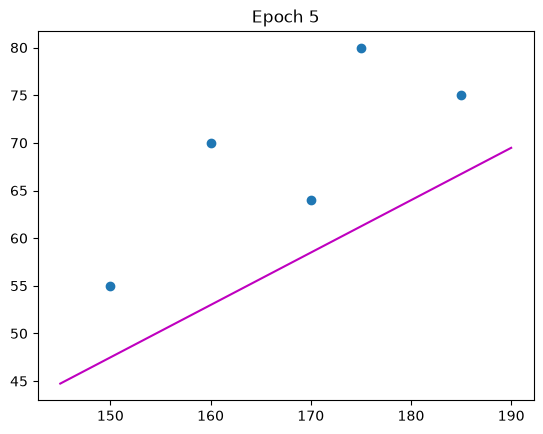

Epoch: 6, train loss: 250.2566
Weight: 0.5609, Bias:-34.9993


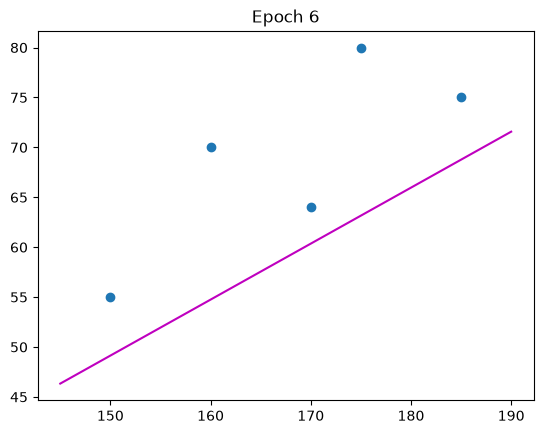

Epoch: 7, train loss: 213.1756
Weight: 0.5701, Bias:-34.9993


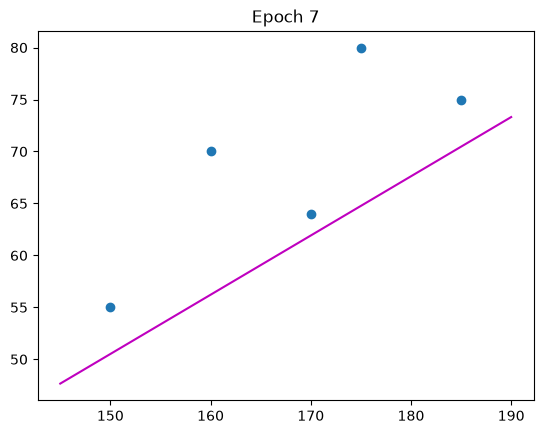

Epoch: 8, train loss: 187.6445
Weight: 0.5777, Bias:-34.9992


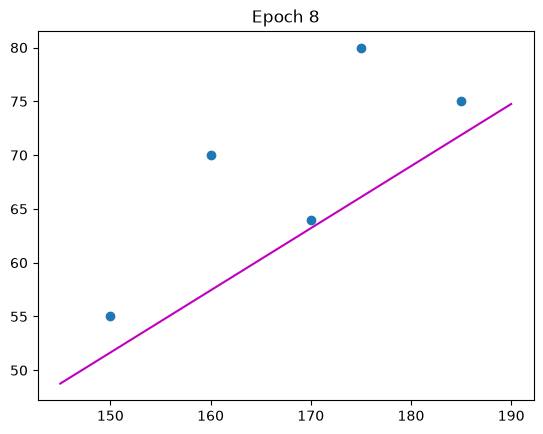

Epoch: 9, train loss: 170.0657
Weight: 0.5840, Bias:-34.9992


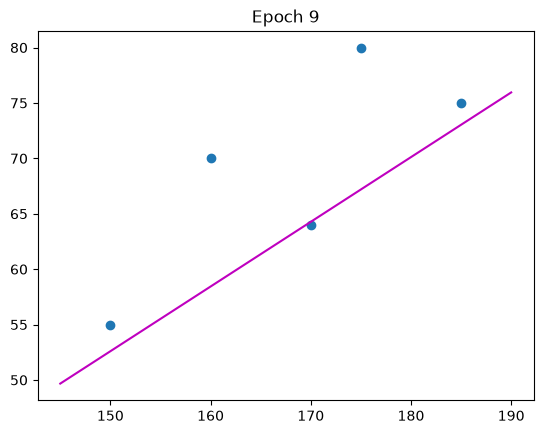

Epoch: 10, train loss: 157.9622
Weight: 0.5892, Bias:-34.9991


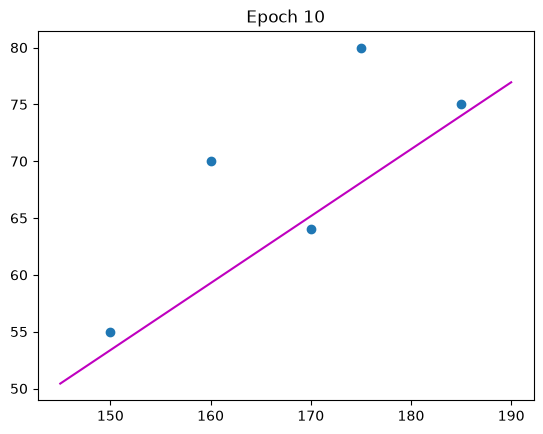

Epoch: 11, train loss: 149.6288
Weight: 0.5935, Bias:-34.9991


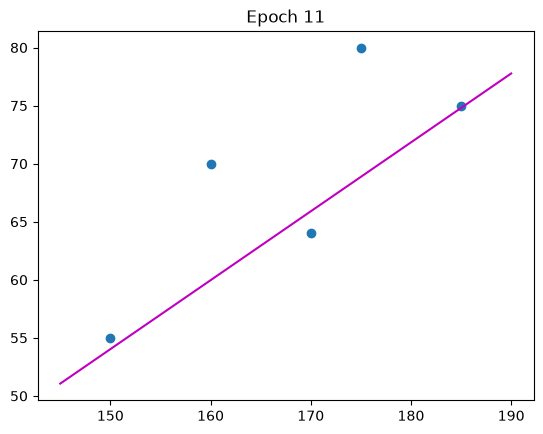

Epoch: 12, train loss: 143.8909
Weight: 0.5971, Bias:-34.9991


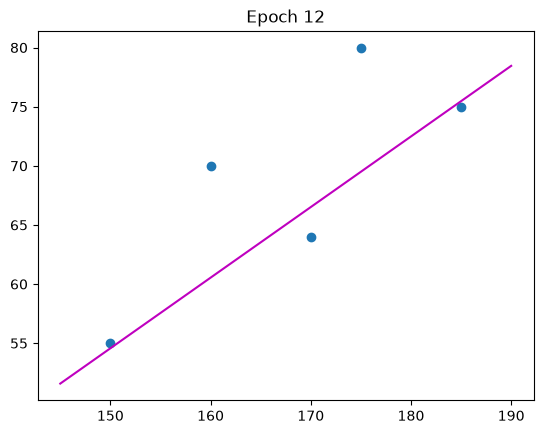

Epoch: 13, train loss: 139.9402
Weight: 0.6001, Bias:-34.9991


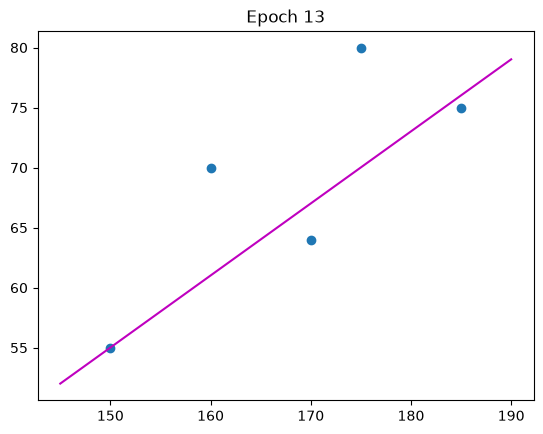

Epoch: 14, train loss: 137.2202
Weight: 0.6026, Bias:-34.9991


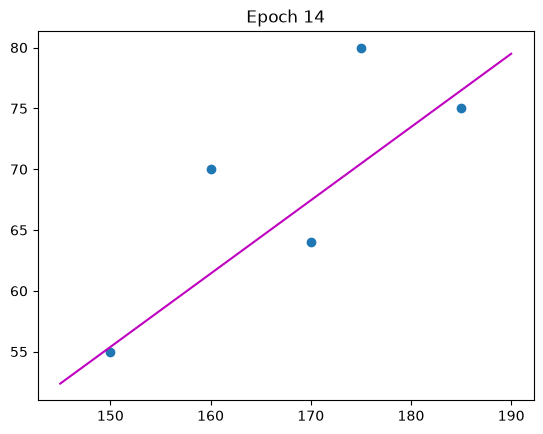

Epoch: 15, train loss: 135.3472
Weight: 0.6046, Bias:-34.9990


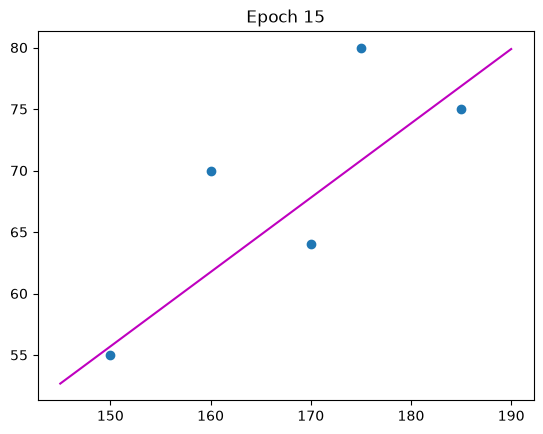

Epoch: 16, train loss: 134.0578
Weight: 0.6064, Bias:-34.9990


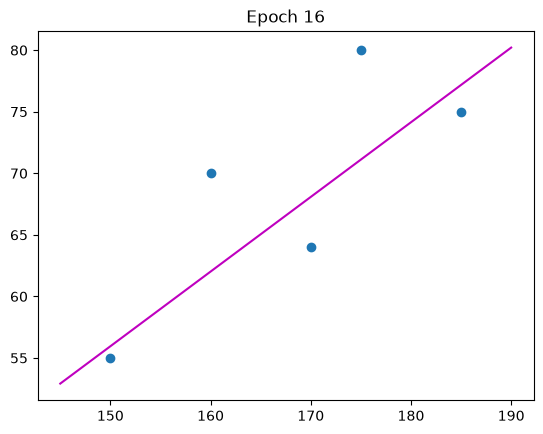

Epoch: 17, train loss: 133.1698
Weight: 0.6078, Bias:-34.9990


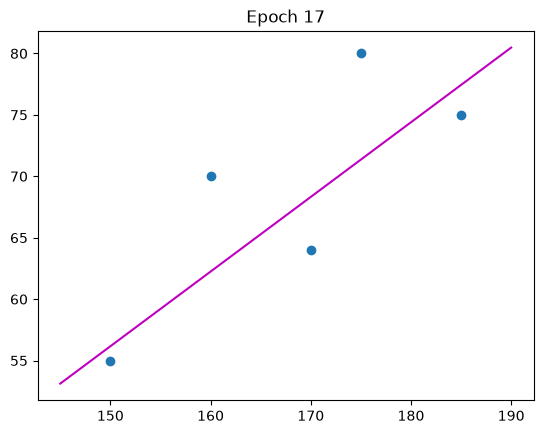

Epoch: 18, train loss: 132.5586
Weight: 0.6089, Bias:-34.9990


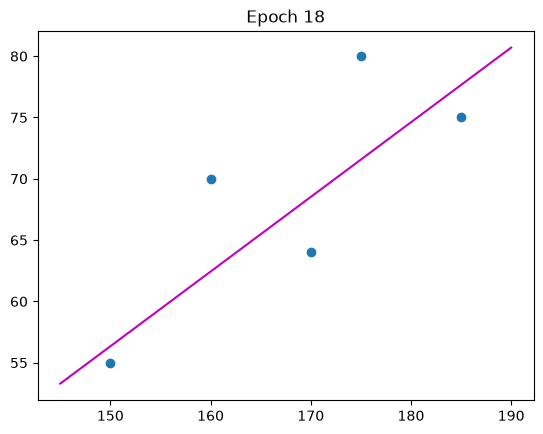

Epoch: 19, train loss: 132.1376
Weight: 0.6099, Bias:-34.9990


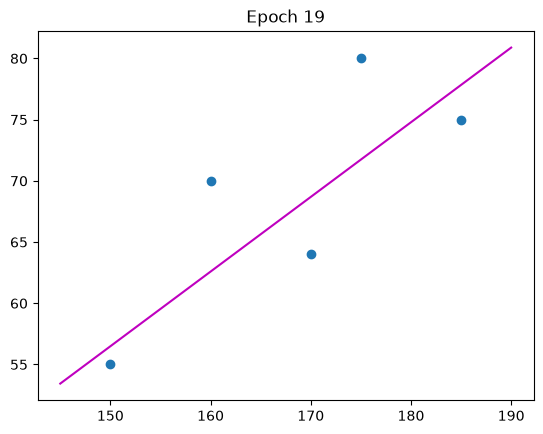

Epoch: 20, train loss: 131.8478
Weight: 0.6107, Bias:-34.9990


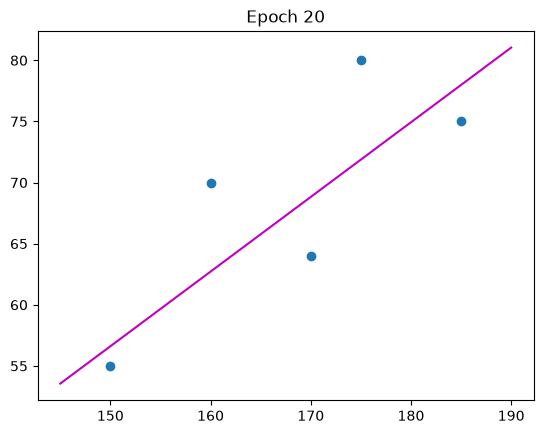

In [28]:
# 위는 어떻게 실행되는지 알기 위해 한 것이고
# 이게 PyTorch 정석
from torch import nn, optim

x=x.reshape(-1, 1)

model=nn.Linear(1, 1)
model.weight.data=torch.tensor([[0.45]])
model.bias.data=torch.tensor([-35.])

LR=3e-6
EPOCH=20

optimizer=optim.SGD(model.parameters(), lr=LR)
cirterion=nn.MSELoss()

loss_history=[]

for ep in range(EPOCH):
    # 예측값
    y_hat=model(x)

    # loss
    loss=cirterion(y_hat, y)

    # update
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    # 출력
    loss_history+=[loss.item()]
    print(f'Epoch: {ep+1}, train loss: {loss.item():.4f}')
    print(f'Weight: {model.weight.data.item():.4f}, Bias:{model.bias.data.item():.4f}')

    x_plot=torch.linspace(145, 190, 100)
    y_plot=model.weight.squeeze().detach()*x_plot+model.bias.detach()
    plt.figure()
    plt.plot(x, y, 'o')
    plt.plot(x_plot, y_plot, 'm')
    plt.title(f'Epoch {ep+1}')
    plt.show()